# Boston Housing: regressione con Kumo Tabular (ONNX)

Predizione del prezzo (`Price`, ex `MEDV`, in migliaia di $) con il modello tabulare di NVIDIA, eseguito con **ONNX Runtime** (niente torch).
Con 506 righe un solo split train/test è poco affidabile: tutto si valuta con **cross-validation a 5 fold**
e prediction *out-of-fold* (ogni casa viene predetta una volta, da un modello che non ha visto il suo prezzo).

1. **Parte 1:** Kumo sulle feature originali, con metriche, intervalli di previsione (quantili) e grafici (`scikit-learn`, `matplotlib`).
2. **Parte 2:** `Pipeline` sklearn con feature engineering (`ColumnTransformer`) + Kumo, confrontata con la stessa pipeline
   con una `RandomForest`, sugli stessi fold. Nel wrapper sklearn `KumoRegressor`, `fit` non addestra niente: chiama solo `set_context`.

In [ ]:
!pip install -q onnxruntime

## 1. Dati

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

path = 'https://frenzy86.s3.eu-west-2.amazonaws.com/IFAO/boston_houses.csv'

df = pd.read_csv(path)
df = df.rename(columns={"MEDV": "Price"})
df

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,Price
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
501,0.06263,0.0,11.93,0,0.573,6.593,69.1,2.4786,1,273,21.0,391.99,9.67,22.4
502,0.04527,0.0,11.93,0,0.573,6.120,76.7,2.2875,1,273,21.0,396.90,9.08,20.6
503,0.06076,0.0,11.93,0,0.573,6.976,91.0,2.1675,1,273,21.0,396.90,5.64,23.9
504,0.10959,0.0,11.93,0,0.573,6.794,89.3,2.3889,1,273,21.0,393.45,6.48,22.0


## 2. Modulo `kumo_onnx.py` e download del modello `.onnx` (regressione)

Tutto il codice del modello (download, preprocessing, classe `KumoTabularONNX`) è nel modulo [`kumo_onnx.py`](https://github.com/Frenz86/kumo/blob/main/kumo_onnx.py) su GitHub: il notebook lo scarica e lo importa direttamente, senza bisogno del file in locale.

Il file `.onnx` (~116 MB) viene salvato in `models/`

In [2]:
import sys, types, urllib.request
from pathlib import Path

# Modulo scaricato da GitHub e caricato in memoria (non serve kumo_onnx.py nella cartella)
KUMO_URL = "https://raw.githubusercontent.com/Frenz86/kumo/main/kumo_onnx.py"
codice = urllib.request.urlopen(KUMO_URL).read().decode("utf-8")
kumo_onnx = types.ModuleType("kumo_onnx")
kumo_onnx.__file__ = str(Path.cwd() / "kumo_onnx.py")  # così il modello .onnx finisce in ./models
exec(compile(codice, KUMO_URL, "exec"), kumo_onnx.__dict__)
sys.modules["kumo_onnx"] = kumo_onnx

from kumo_onnx import KumoRegressor, KumoTabularONNX, download_model

print("regression ->", download_model("regression"))

small_regression.onnx: 120/120 MB
regression -> C:\Users\danie\Il mio Drive\Lesson\IFOA\ML-AI_8\21_Mod_in_context\Kumo\models\small_regression.onnx


# Parte 1: Kumo sulle feature originali

## 3. Feature e fold della cross-validation

Tolgo la colonna `B`: è calcolata dalla percentuale di residenti afroamericani ed è il motivo per cui scikit-learn ha rimosso questo dataset.
Le altre 12 colonne sono tutte numeriche e senza valori mancanti; Kumo le normalizza internamente, quindi non serve uno `StandardScaler`.

I 5 fold vengono da `KFold` con `shuffle=True` (per la regressione non c'è una classe su cui stratificare).
Gli stessi fold si usano per tutti i modelli del notebook, così i confronti sono sulle stesse case.

In [3]:
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold

TARGET = "Price"
DROP = ["B"]

X = df.drop(columns=[TARGET] + DROP)
y = df[TARGET].to_numpy(dtype=float)

folds = list(KFold(n_splits=5, shuffle=True, random_state=0).split(X))  # [(indici contesto, indici test), ...]

print(f"{len(y)} righe, feature = {list(X.columns)}")
print(f"prezzo medio nel dataset: {y.mean():.2f}")
for f, (tr, te) in enumerate(folds):
    print(f"fold {f}: contesto = {len(tr)} righe, test = {len(te)} righe, prezzo medio nel test = {y[te].mean():.2f}")

506 righe, feature = ['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'LSTAT']
prezzo medio nel dataset: 22.53
fold 0: contesto = 404 righe, test = 102 righe, prezzo medio nel test = 22.22
fold 1: contesto = 405 righe, test = 101 righe, prezzo medio nel test = 22.21
fold 2: contesto = 405 righe, test = 101 righe, prezzo medio nel test = 22.01
fold 3: contesto = 405 righe, test = 101 righe, prezzo medio nel test = 23.47
fold 4: contesto = 405 righe, test = 101 righe, prezzo medio nel test = 22.76


## 4. Prediction out-of-fold

Kumo non si addestra: i pesi del modello `.onnx` sono pre-addestrati e restano fissi (*in-context learning*).
`set_context()` memorizza solo le righe etichettate; in `predict` il modello le legge insieme alle righe da predire,
come gli esempi in un prompt, e da lì deduce le risposte.

Per la regressione Kumo non dà un solo numero ma una **distribuzione** (999 quantili): `predict` ne restituisce la media,
`predict_quantiles` i quantili scelti, qui il 10% e il 90% per avere un intervallo di previsione.

Per ogni fold: le altre 4/5 delle righe fanno da contesto, le righe del fold vengono predette.
Alla fine ogni casa ha una prediction calcolata **senza** che il suo prezzo fosse nel contesto.

In [4]:
def kumo_oof(model, X, y, folds, quantiles=(0.1, 0.9)):
    # Prediction out-of-fold (media) e quantili [n_righe, len(quantiles)]: per ogni fold il modello riceve
    # come contesto le altre righe (set_context sostituisce il contesto precedente) e predice quelle del fold
    pred = np.zeros(len(y))
    q = np.zeros((len(y), len(quantiles)))
    for tr, te in folds:
        model.set_context(X.iloc[tr], y[tr])
        pred[te] = model.predict(X.iloc[te])
        q[te] = model.predict_quantiles(X.iloc[te], quantiles)
    return pred, q


kumo = KumoTabularONNX("regression", n_estimators=8, seed=0)
y_pred, q = kumo_oof(kumo, X, y, folds)  # y_pred = media della distribuzione predetta
q10, q90 = q.T                            # intervallo 10%-90%

pd.DataFrame({"vero": y, "predetto": y_pred.round(2), "p10": q10.round(2), "p90": q90.round(2)}).head(10)

,vero,predetto,p10,p90
0,24.0,24.09,18.89,29.53
1,21.6,23.61,21.08,26.24
2,34.7,30.59,27.20,34.16
3,33.4,35.30,31.94,38.88
4,36.2,32.01,29.12,34.91
5,28.7,25.12,23.16,27.21
6,22.9,20.40,19.15,21.66
7,27.1,16.28,14.51,18.25
8,16.5,13.82,11.14,16.44
9,18.9,18.54,15.72,21.44


## 5. Metriche: R², MAE, RMSE, MAPE e copertura degli intervalli

Le metriche sono calcolate su tutte le 506 prediction out-of-fold; l'R² per fold mostra quanto varia il risultato da un fold all'altro.
La **copertura** è la percentuale di prezzi veri che cadono nell'intervallo 10%-90%: se i quantili sono ben calibrati dovrebbe essere circa 80%.

In [5]:
def regression_report(y_true, y_hat):
    return {"R2": r2_score(y_true, y_hat), "MAE": mean_absolute_error(y_true, y_hat),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_hat)),
            "MAPE %": 100 * mean_absolute_percentage_error(y_true, y_hat)}


def fold_r2(y, pred, folds):
    # R² calcolato separatamente su ogni fold
    return np.array([r2_score(y[te], pred[te]) for _, te in folds])


metrics = regression_report(y, y_pred)
r2s = fold_r2(y, y_pred, folds)

for k, v in metrics.items():
    print(f"{k:>7} = {v:.4f}")
print(f"\nR2 per fold = {r2s.round(3)}   media = {r2s.mean():.4f} ± {r2s.std():.4f}")
print(f"copertura intervallo 10%-90%: {((y >= q10) & (y <= q90)).mean():.1%} (atteso circa 80%)")

     R2 = 0.9050
    MAE = 1.7391
   RMSE = 2.8313
 MAPE % = 8.8371

R2 per fold = [0.804 0.934 0.831 0.945 0.972]   media = 0.8973 ± 0.0671
copertura intervallo 10%-90%: 81.4% (atteso circa 80%)


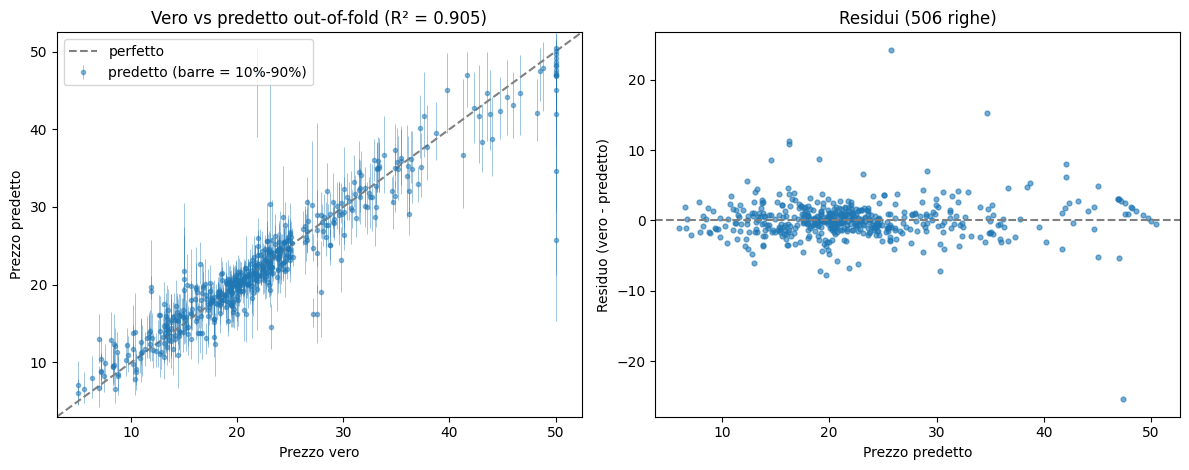

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8))

lim = [min(y.min(), y_pred.min()) - 2, max(y.max(), y_pred.max()) + 2]
ax1.errorbar(y, y_pred, yerr=[y_pred - q10, q90 - y_pred], fmt="o", ms=3, alpha=0.5, elinewidth=0.6,
             label="predetto (barre = 10%-90%)")
ax1.plot(lim, lim, "--", color="gray", label="perfetto")
ax1.set(xlim=lim, ylim=lim, xlabel="Prezzo vero", ylabel="Prezzo predetto",
        title=f"Vero vs predetto out-of-fold (R² = {metrics['R2']:.3f})")
ax1.legend(loc="upper left")

ax2.scatter(y_pred, y - y_pred, s=12, alpha=0.6)
ax2.axhline(0, ls="--", color="gray")
ax2.set(xlabel="Prezzo predetto", ylabel="Residuo (vero - predetto)", title="Residui (506 righe)")
plt.tight_layout()
plt.show()

# Parte 2: Pipeline sklearn con feature engineering

## 6. Feature engineering come `ColumnTransformer` + Kumo

Ogni nuova feature è un `FunctionTransformer` che lavora solo sulle colonne che gli servono:

- `LstatPerRoom` = `LSTAT` / `RM` (quota di popolazione a basso reddito rispetto alla grandezza delle case);
- `TaxPerRoom` = `TAX` / `RM` (tasse sulla proprietà per stanza);
- `Rad24` = 1 se `RAD` = 24, cioè il gruppo di zone con il massimo accesso autostradale (il centro di Boston).

Le colonne originali passano invariate (`passthrough`), `B` viene scartata (`remainder="drop"`).
Con `set_output(transform="pandas")` l'uscita resta un DataFrame con i nomi delle colonne.

L'ultimo step è `KumoRegressor` (in `kumo_onnx.py`): la `Pipeline` chiama `fit`, che per Kumo vuol dire solo `set_context`.
Lo stesso step `features` si riusa nella pipeline della RandomForest.

In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer


def lstat_per_room(data):
    return (data["LSTAT"] / data["RM"]).to_frame("LstatPerRoom")


def tax_per_room(data):
    return (data["TAX"] / data["RM"]).to_frame("TaxPerRoom")


def rad_24(data):
    return (data["RAD"] == 24).astype(int).to_frame("Rad24")


def new_feature(func, name):
    return FunctionTransformer(func, feature_names_out=lambda transformer, cols: [name])


KEEP = ["CRIM", "ZN", "INDUS", "CHAS", "NOX", "RM", "AGE", "DIS", "RAD", "TAX", "PTRATIO", "LSTAT"]

features = ColumnTransformer([
                            ("keep", "passthrough", KEEP),
                            ("lstat_room", new_feature(lstat_per_room, "LstatPerRoom"), ["LSTAT", "RM"]),
                            ("tax_room", new_feature(tax_per_room, "TaxPerRoom"), ["TAX", "RM"]),
                            ("rad24", new_feature(rad_24, "Rad24"), ["RAD"]),
                            ], remainder="drop", verbose_feature_names_out=False).set_output(transform="pandas")

kumo_pipe = Pipeline([
                    ("features", features),
                    ("regressor", KumoRegressor(n_estimators=8, seed=0)),
                    ])

X_raw = df.drop(columns=[TARGET])

# Esempio: contesto = righe fuori dal fold 0, predict sulle righe grezze del fold 0
tr, te = folds[0]
kumo_pipe.fit(X_raw.iloc[tr], y[tr])  # fit = set_context, nessun training
print("colonne viste da Kumo:", list(kumo_pipe[:-1].transform(X_raw.iloc[:1]).columns))
pd.DataFrame({"vero": y[te], "predetto": kumo_pipe.predict(X_raw.iloc[te]).round(2)}, index=X_raw.index[te]).head(10)

colonne viste da Kumo: ['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'LSTAT', 'LstatPerRoom', 'TaxPerRoom', 'Rad24']


,vero,predetto
1,21.6,23.49
10,15.0,21.90
12,21.7,22.82
15,19.9,20.01
21,19.6,16.47
37,21.0,21.44
45,19.3,20.70
46,20.0,21.01
54,18.9,17.24
56,24.7,23.60


In [8]:
pred_fe = cross_val_predict(kumo_pipe, X_raw, y, cv=folds)  # la pipeline riceve i dati grezzi
r2s_fe = fold_r2(y, pred_fe, folds)
print("Kumo + feature engineering:", {k: round(float(v), 4) for k, v in regression_report(y, pred_fe).items()})
print(f"R2 per fold = {r2s_fe.round(3)}   media = {r2s_fe.mean():.4f} ± {r2s_fe.std():.4f}")

Kumo + feature engineering: {'R2': 0.8998, 'MAE': 1.7504, 'RMSE': 2.9077, 'MAPE %': 8.8195}
R2 per fold = [0.785 0.934 0.829 0.94  0.971]   media = 0.8920 ± 0.0718


## 7. Confronto con una pipeline classica (RandomForest)

Qui non ci sono valori mancanti né colonne di testo, quindi alla RandomForest basta lo stesso step `features` della pipeline Kumo.
`cross_val_predict` addestra la pipeline su ogni fold (qui il training c'è davvero) e restituisce le prediction out-of-fold.

In [9]:
from sklearn.ensemble import RandomForestRegressor

rf_pipe = Pipeline([
                    ("features", features),
                    ("regressor", RandomForestRegressor(n_estimators=300, random_state=0)),
                    ])

pred_rf = cross_val_predict(rf_pipe, X_raw, y, cv=folds)
r2s_rf = fold_r2(y, pred_rf, folds)
print("Pipeline RandomForest:", {k: round(float(v), 4) for k, v in regression_report(y, pred_rf).items()})
print(f"R2 per fold = {r2s_rf.round(3)}   media = {r2s_rf.mean():.4f} ± {r2s_rf.std():.4f}")

Pipeline RandomForest: {'R2': 0.8225, 'MAE': 2.3792, 'RMSE': 3.8709, 'MAPE %': 12.1299}
R2 per fold = [0.718 0.912 0.816 0.72  0.921]   media = 0.8176 ± 0.0885


## 8. Riepilogo

Stessi fold e stesse 506 righe per tutti i modelli. La colonna ± è la deviazione standard dell'R² tra i fold:
se gli intervalli si sovrappongono molto, la differenza tra due modelli non è affidabile.

Su questo dataset il feature engineering cambia poco per Kumo: il modello applica già da solo trasformazioni
non lineari alle colonne (Yeo-Johnson, rank gaussiano...), quindi rapporti come `LstatPerRoom` aggiungono poca informazione nuova.

modello                      R2      MAE     RMSE   MAPE %         R2 per fold
Kumo                     0.9050    1.739    2.831     8.84      0.8973 ± 0.0671
Kumo + feature eng.      0.8998    1.750    2.908     8.82      0.8920 ± 0.0718
RandomForest             0.8225    2.379    3.871    12.13      0.8176 ± 0.0885


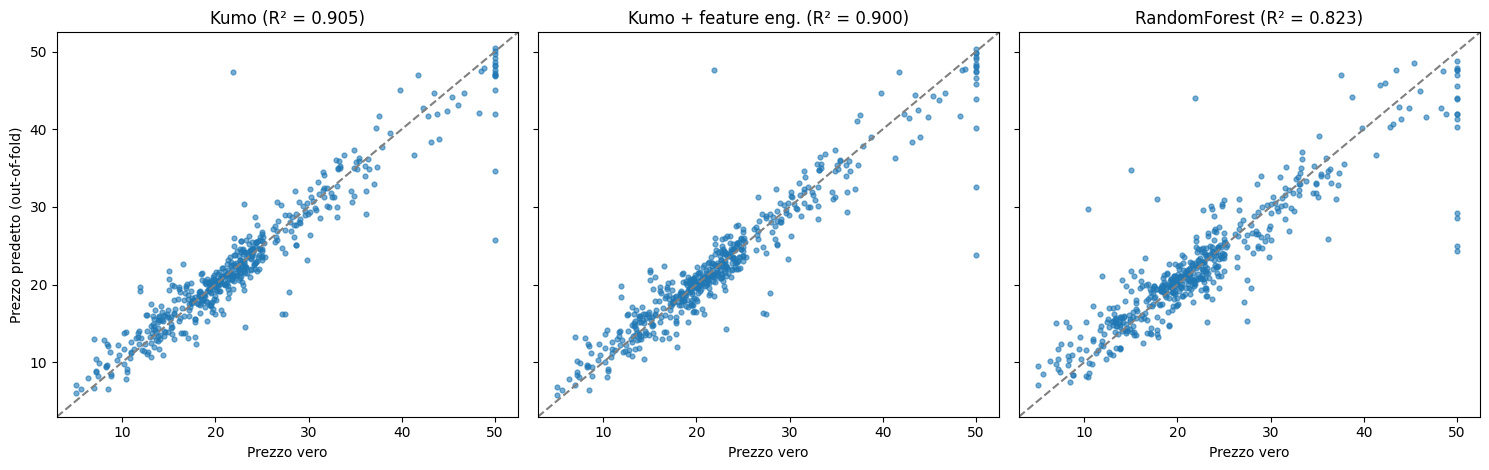

In [10]:
results = [("Kumo", y_pred, r2s),
           ("Kumo + feature eng.", pred_fe, r2s_fe),
           ("RandomForest", pred_rf, r2s_rf)]

print(f"{'modello':22s}{'R2':>9}{'MAE':>9}{'RMSE':>9}{'MAPE %':>9}{'R2 per fold':>20}")
for name, p, r in results:
    m = regression_report(y, p)
    print(f"{name:22s}{m['R2']:>9.4f}{m['MAE']:>9.3f}{m['RMSE']:>9.3f}{m['MAPE %']:>9.2f}{r.mean():>12.4f} ± {r.std():.4f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharey=True)
for ax, (name, p, _) in zip(axes, results):
    ax.scatter(y, p, s=12, alpha=0.6)
    ax.plot(lim, lim, "--", color="gray")
    ax.set(xlim=lim, ylim=lim, xlabel="Prezzo vero", title=f"{name} (R² = {r2_score(y, p):.3f})")
axes[0].set_ylabel("Prezzo predetto (out-of-fold)")
plt.tight_layout()
plt.show()